# Analyse BRS Event Data

Interactive **sixdegrees** analysis for one BRS event at LIGO **LIV**. This notebook:

- Loads the event YAML from `output/event_<date><postfix>/` (combined MiniSEED from `02_brs_prepare_data`, config from `01_brs_make_config`)
- Fetches event metadata (USGS), loads and trims waveforms, filters, and runs rotation–translation cross-correlation
- Estimates **backazimuth** (Rayleigh, max/mid CC methods) and compares results to the theoretical backazimuth
- Computes phase **velocities** and **Rayleigh dispersion curves** (velocity, then acceleration after differentiation)
- Produces diagnostic plots (waveform CC, CWT/backazimuth, velocities, dispersion traces/curves, event overview) with optional figure export

Set `date`, `postfix` (e.g. `_01` when several events share a calendar date), and `save_figs` in the configuration cells below. Batch processing of many events is available in **03_brs_analysis_v2.py**.

Each `output/event_*` folder needs a matching `<YYYYMMDD>.yml` (create with **01_brs_make_config.ipynb**, copy into the event folder, and set `path_to_mseed_file` to the prepared `.mseed`).

This notebook is automated in: **03_brs_analysis.py**

In [1]:
import os
import yaml
import numpy as np
import matplotlib.pyplot as plt
from obspy import UTCDateTime
from sixdegrees.sixdegrees import sixdegrees

from sixdegrees.plots.plot_waveform_cc import plot_waveform_cc
from sixdegrees.plots.plot_cwt_all import plot_cwt_all
from sixdegrees.plots.plot_velocities import plot_velocities
from sixdegrees.plots.plot_backazimuth_results import plot_backazimuth_results
from sixdegrees.plots.plot_spectra import plot_spectra
from sixdegrees.plots.plot_event_overview import plot_event_overview
from sixdegrees.plots.plot_dispersion_curves import plot_dispersion_curves
from sixdegrees.plots.plot_dispersion_traces import plot_dispersion_traces


## Configurations

Load configuration file

This can be prepared using the *brs_make_config.ipynb* notebook

In [2]:
# select date
# date = "20230206"
date = "20240628"

# select postfix
postfix=""

# save figures
save_figs = False

# get config from yaml file
config = sixdegrees.load_from_yaml(f"./output/event_{date}{postfix}/{date}")


In [3]:
config

{'data_source': 'mseed_file',
 'magnitude': 7.2,
 'origin_time': '2024-06-28 05:36:36',
 'path_to_data_out': './output/',
 'path_to_figures': './figures/',
 'path_to_inv_rot': './metadata/LIGO_HAN_LIV_AB.xml',
 'path_to_inv_tra': './metadata/LIGO_HAN_LIV_AB.xml',
 'path_to_mseed_file': './output/event_20240628/20240628.mseed',
 'project': 'event_20240628',
 'resample_rate': 10,
 'rot_seed': ['LI.LIV..DJZ', 'LI.LIV..DJN', 'LI.LIV..DJE'],
 'rot_remove_response': False,
 'rotate_zne': False,
 'runit': 'rad',
 'seed': 'LI.LIV..',
 'station_lat': 30.56289,
 'station_lon': -90.77424,
 'tbeg': '2024-06-28 05:40:00',
 'tend': '2024-06-28 06:30:00',
 'tra_output': 'VEL',
 'tra_remove_response': False,
 'tra_seed': ['LI.LIV..DHZ', 'LI.LIV..DHN', 'LI.LIV..DHE'],
 'tunit': 'm/s',
 'verbose': True,
 'workdir': './output/event_20240628/'}

Create directory for plotting outputs

In [4]:
if save_figs:
    # create a folder for the project figures
    if not os.path.exists(f"./figures/{config['project']}"):
        os.makedirs(f"./figures/{config['project']}")

    # update the path to the figures
    config['path_to_figures'] = f"./figures/{config['project']}/"

Setup a sixdegrees instance

In [5]:
sd = sixdegrees(conf=config)

Get key information about the event

In [6]:
ev = sd.get_event_info(
    origin_time=config['origin_time'],
    base_catalog="USGS",
    magnitude=config['magnitude'],
    time_margin=1000
)

Found event:
Origin time: 2024-06-28T05:36:36.902000Z
Magnitude: 7.2 mww
Location: -15.828°N, -74.454°E
Depth: 24.0 km
Epicentral Distance: 5422.81 km
Epicentral Distance: 48.8°
Backazimuth: 158.89°


In [7]:
# # manually set event information (if not obtained from client)
# ev = {
#     'latitude': 52.55,
#     'longitude': 160.10,
#     'depth_km': 21,
#     'magnitude': 8.8,
# }

# #compute backazimuth and distance
# from obspy.geodetics import gps2dist_azimuth

# dist, az, baz = gps2dist_azimuth(ev['latitude'], ev['longitude'], config['station_lat'], config['station_lon'])

# ev['distance_km'] = dist / 1000
# ev['backazimuth'] = baz

This will load the data from the data source:
- local mseed file
- local sds system
- fdsn (online)

and trim it to the time window

In [8]:
sd.load_data(config['tbeg'], config['tend'], resample_rate=config['resample_rate'])

-> fetching LI.LIV..DHZ data from mseed file
-> fetching LI.LIV..DHN data from mseed file
-> fetching LI.LIV..DHE data from mseed file
-> translation inventory provided: ./metadata/LIGO_HAN_LIV_AB.xml
3 Trace(s) in Stream:
LI.LIV..DHZ | 2024-06-28T05:39:59.000000Z - 2024-06-28T06:30:01.000000Z | 512.0 Hz, 1537025 samples
LI.LIV..DHN | 2024-06-28T05:39:59.000000Z - 2024-06-28T06:30:01.000000Z | 512.0 Hz, 1537025 samples
LI.LIV..DHE | 2024-06-28T05:39:59.000000Z - 2024-06-28T06:30:01.000000Z | 512.0 Hz, 1537025 samples
-> fetching LI.LIV..DJZ data from mseed file
-> fetching LI.LIV..DJN data from mseed file
-> fetching LI.LIV..DJE data from mseed file
-> rotation inventory provided: ./metadata/LIGO_HAN_LIV_AB.xml
3 Trace(s) in Stream:
LI.LIV..DJZ | 2024-06-28T05:39:59.000000Z - 2024-06-28T06:30:01.000000Z | 256.0 Hz, 768513 samples
LI.LIV..DJN | 2024-06-28T05:39:59.000000Z - 2024-06-28T06:30:01.000000Z | 256.0 Hz, 768513 samples
LI.LIV..DJE | 2024-06-28T05:39:59.000000Z - 2024-06-28T06:3

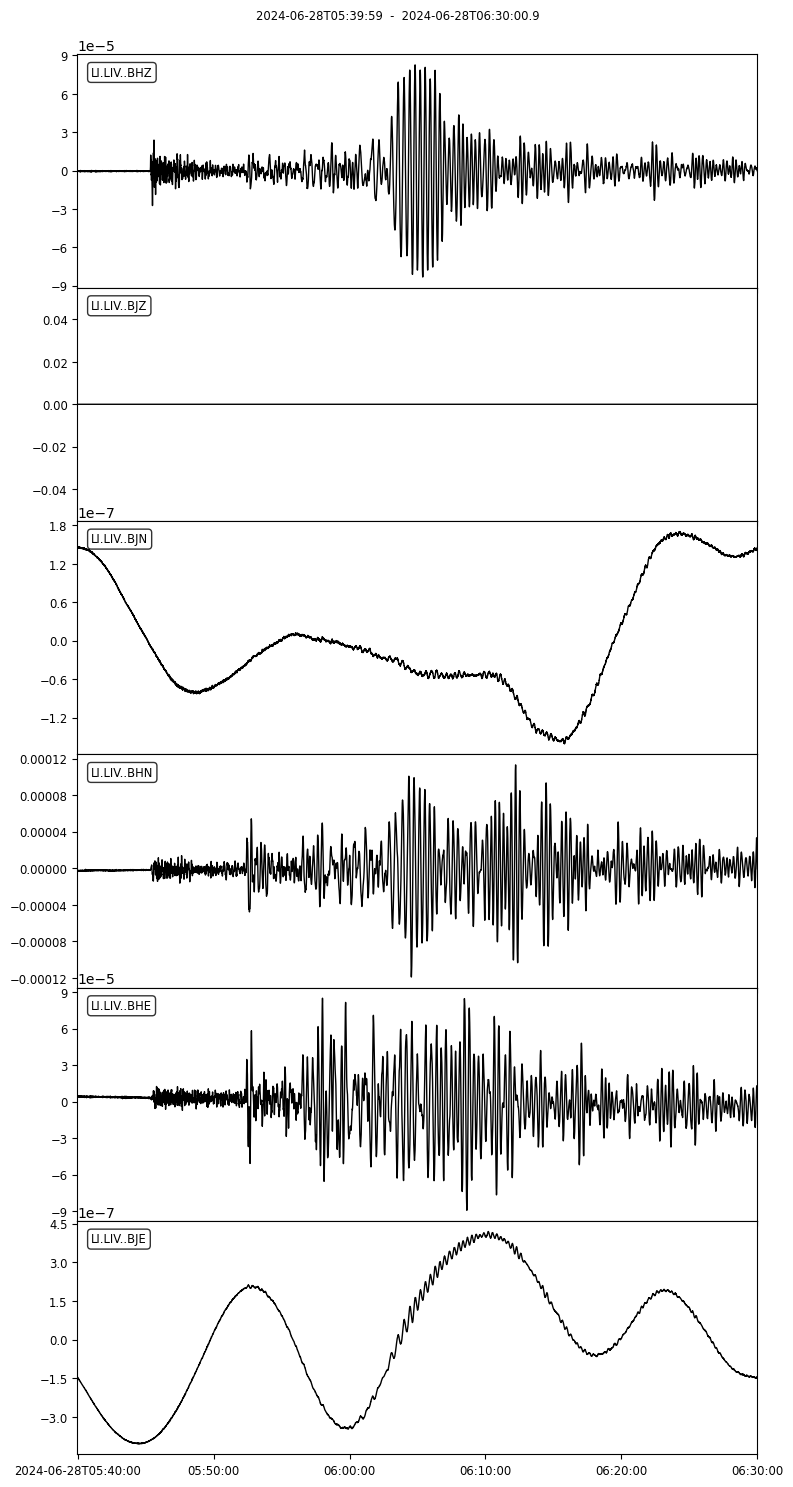

In [9]:
sd.st.plot(equal_scale=False);

Ensure that all traces of stream have the same sample size

In [10]:
sd.trim_stream(set_common=True, set_interpolate=True)

 -> trim_stream: window 2024-06-28T05:39:59.000000Z -> 2024-06-28T06:30:00.900000Z
    initial npts=[30020, 30020, 30020, 30020, 30020, 30020], rates=[10.0]
    linear interpolation -> 10.0 Hz, anchored at 2024-06-28T05:39:59.000000Z
    final: starttimes={'2024-06-28T05:39:59.000000Z'}, npts={30020}, rates={10.0}


Apply polarity correction if needed. This is applied to the stream object that is processed. If raw is True, the polarity correction is applied to the raw stream too.

In [11]:
# sd.polarity_stream(pol_dict={"HZ": 1, "JZ": 1, "JX": 1, "JY": 1}, raw=True)

## Analysis

Specify parameters to use for the analysis


In [20]:
# frequency band
fmin, fmax = 0.02, 0.2

# window factor
Twindow = 50 # seconds

# overlap
Toverlap = 0.75

# cross-correlation threshold
cc_threshold = 0.8


Frequency band to filter (this is applied to the stream object after being reset to raw stream)

In [21]:
sd.filter_data(fmin=fmin, fmax=fmax, output=False)

In [22]:
sd.st

6 Trace(s) in Stream:
LI.LIV..BHZ | 2024-06-28T05:39:59.000000Z - 2024-06-28T06:30:00.900000Z | 10.0 Hz, 30020 samples
LI.LIV..BHN | 2024-06-28T05:39:59.000000Z - 2024-06-28T06:30:00.900000Z | 10.0 Hz, 30020 samples
LI.LIV..BHE | 2024-06-28T05:39:59.000000Z - 2024-06-28T06:30:00.900000Z | 10.0 Hz, 30020 samples
LI.LIV..BJZ | 2024-06-28T05:39:59.000000Z - 2024-06-28T06:30:00.900000Z | 10.0 Hz, 30020 samples
LI.LIV..BJN | 2024-06-28T05:39:59.000000Z - 2024-06-28T06:30:00.900000Z | 10.0 Hz, 30020 samples
LI.LIV..BJE | 2024-06-28T05:39:59.000000Z - 2024-06-28T06:30:00.900000Z | 10.0 Hz, 30020 samples

IF required, one can adjust the time window with trim

In [23]:
# sd.trim(UTCDateTime(config['tbeg'])+200, UTCDateTime(config['tend'])-700)

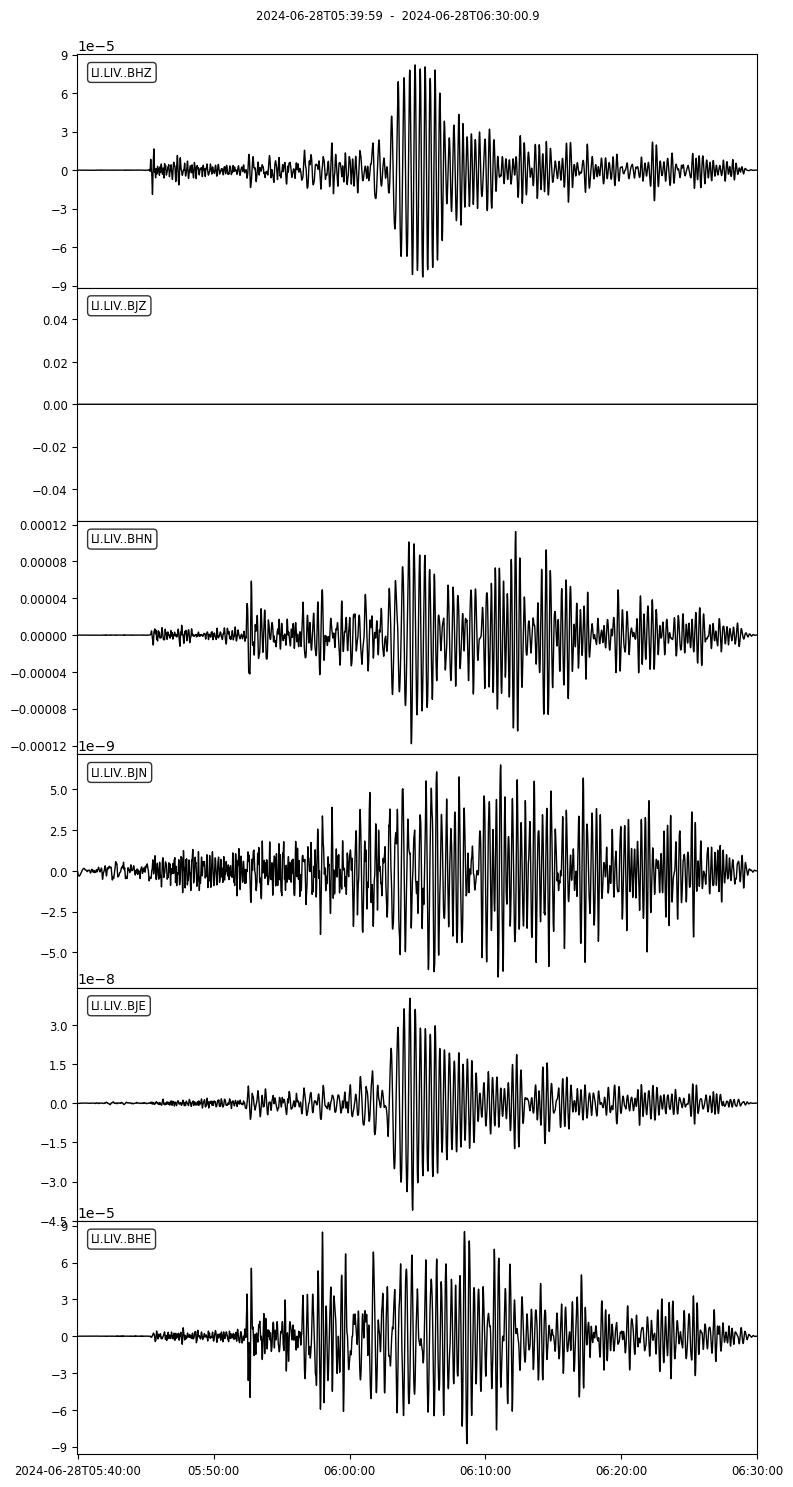

In [24]:
sd.st.plot(equal_scale=False);

Correct horizontal acceleration data with tilt data

In [25]:
# sd.correct_tilt()

In [26]:
# get cross-correlation function of JT and HZ and find the lag
from obspy.signal.cross_correlation import correlate, xcorr_max
from obspy.signal.rotate import rotate_ne_rt

JN = sd.get_stream("rotation").select(channel="*N")[0].data
JE = sd.get_stream("rotation").select(channel="*E")[0].data

JR, JT = rotate_ne_rt(JN, JE, ev['backazimuth'])

HZ = sd.get_stream("translation").select(channel="*Z")[0].data

cc0_before = correlate(JT, HZ, 0)

ccX = correlate(JT, HZ, len(JT))

lag, cc_max = xcorr_max(ccX, abs_max=False) # only positive maxima

HZ = np.roll(HZ, lag)

cc0_after = correlate(JT, HZ, 0)

print("with zero lag: ", round(cc0_before[0], 2), " and with lag samples: ", lag, " > ", round(cc0_after[0], 2))

# apply shift
# sd.st.select(channel="*HZ")[0].data = HZ


with zero lag:  0.82  and with lag samples:  5  >  0.83


# Plotting

let's compare the waveforms of the rotation (red) and translational (black) components 

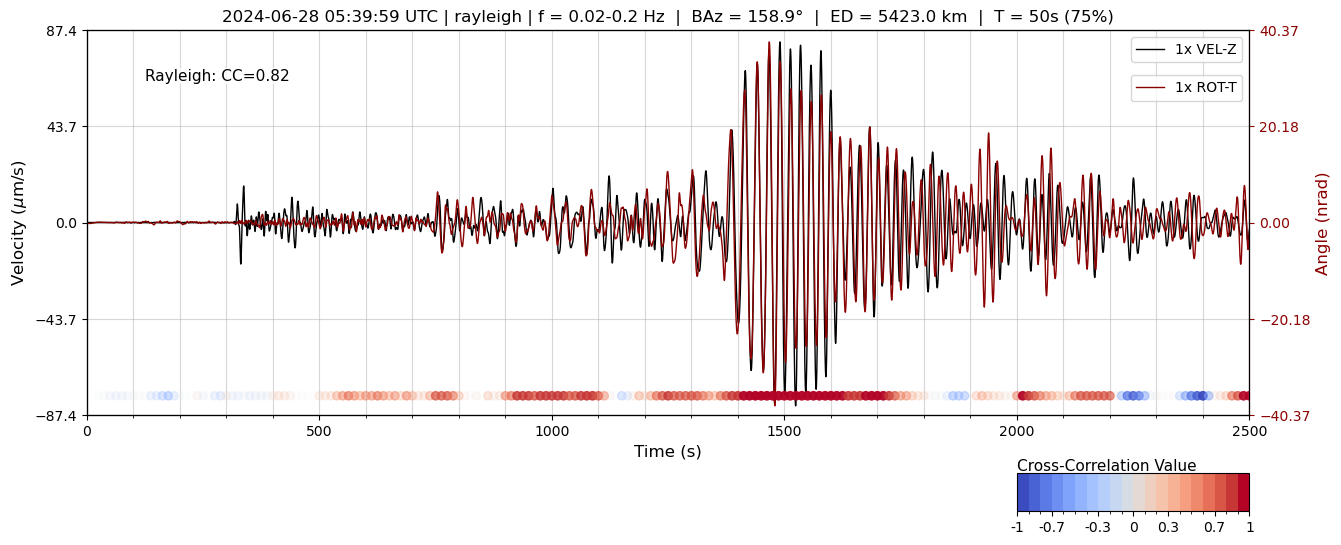

In [33]:
fig = plot_waveform_cc(
    sd_object=sd,
    fmin=fmin,
    fmax=fmax,
    twin_sec=Twindow,
    twin_overlap=Toverlap,
    wave_type="rayleigh",
    runit=config['runit'],
    tunit=config['tunit'],
    data_type="velocity"
)

plt.xlim(0, 2500)
plt.show();

# if save_figs:
fig.savefig(f"{config['path_to_figures']}{config['project']}_VEL_waveform_cc.png", dpi=200, bbox_inches='tight')


In [24]:
# fig = plot_spectra(
#     sd_object=sd,
#     ylog=False,
#     xlog=False,
#     fill=True,
#     data_type="velocity"
# )

# if save_figs:
#     fig.savefig(f"{config['path_to_figures']}{config['project']}_VEL_spectra.png", bbox_inches='tight')


### Backazimuth Estimate

In [34]:
# compute backazimuth
baz_results = sd.compute_backazimuth(
    wave_type='rayleigh',
    baz_step=1,
    baz_win_sec=Twindow,
    baz_win_overlap=Toverlap,
    out=True
)


baz_max = 200, baz_std = 58


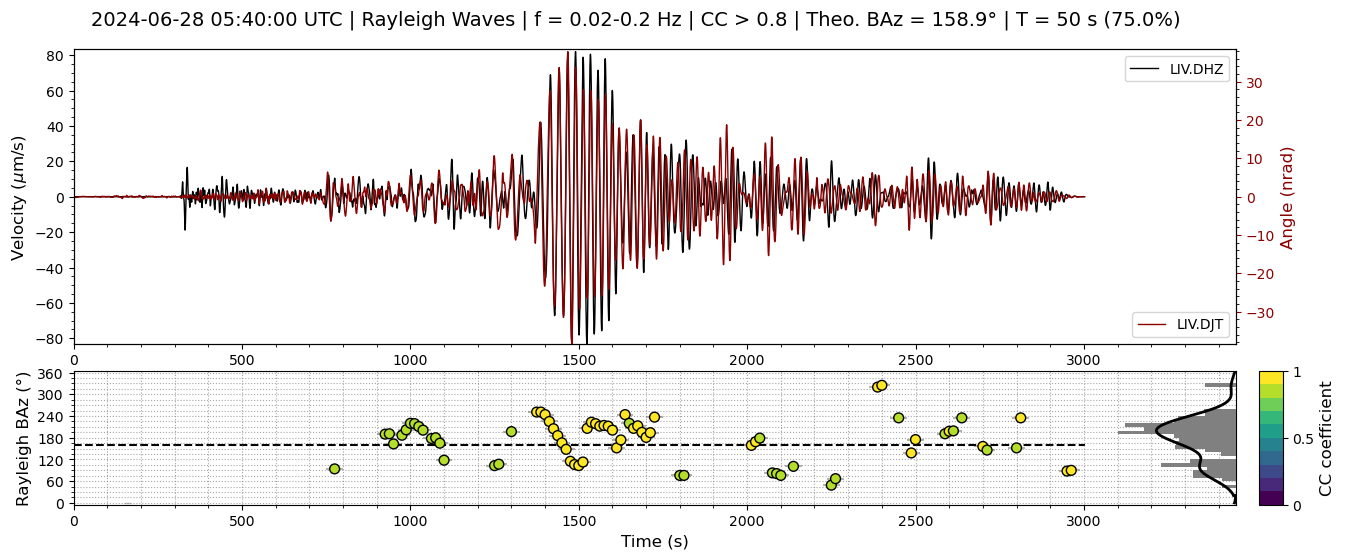

In [35]:
fig = plot_backazimuth_results(
    sd,
    baz_results=baz_results,
    wave_type='rayleigh',
    baz_theo=ev['backazimuth'],
    cc_threshold=cc_threshold,  # optional
    cc_method='max',
    unitscale='nano', # for rotation rate
    data_type="velocity"
)

if save_figs:
    fig.savefig(f"{config['path_to_figures']}{config['project']}_VEL_backazimuth_max.png", bbox_inches='tight')

baz_max = 177, baz_std = 45


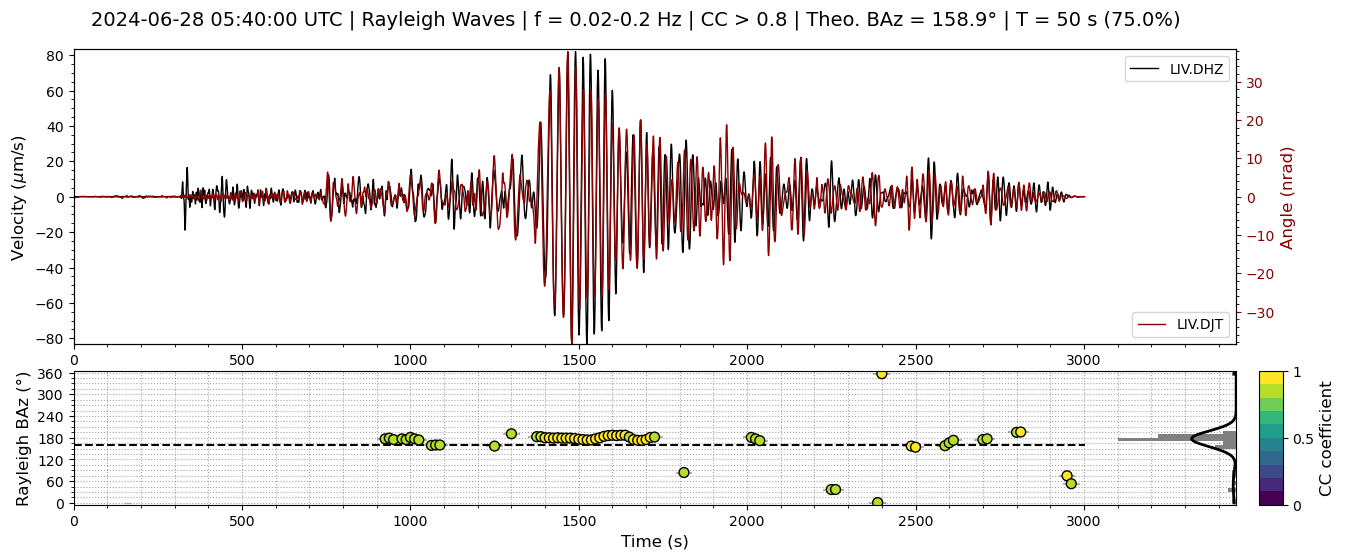

In [37]:
fig = plot_backazimuth_results(
    sd,
    baz_results,
    wave_type='rayleigh',
    baz_theo=ev['backazimuth'],
    cc_threshold=cc_threshold,  # optional
    cc_method='mid',
    unitscale='nano', # for rotation rate
    data_type="velocity"
)

# if save_figs:
fig.savefig(f"{config['path_to_figures']}{config['project']}_VEL_backazimuth_mid.png", dpi=200,bbox_inches='tight')

Using precomputed rayleigh backazimuth results

Estimated BAz Rayleigh = 177° (CC ≥ 0.8)
Computing tangent wave backazimuth...

Estimated BAz Tangent = 177° (CC ≥ 0.8)


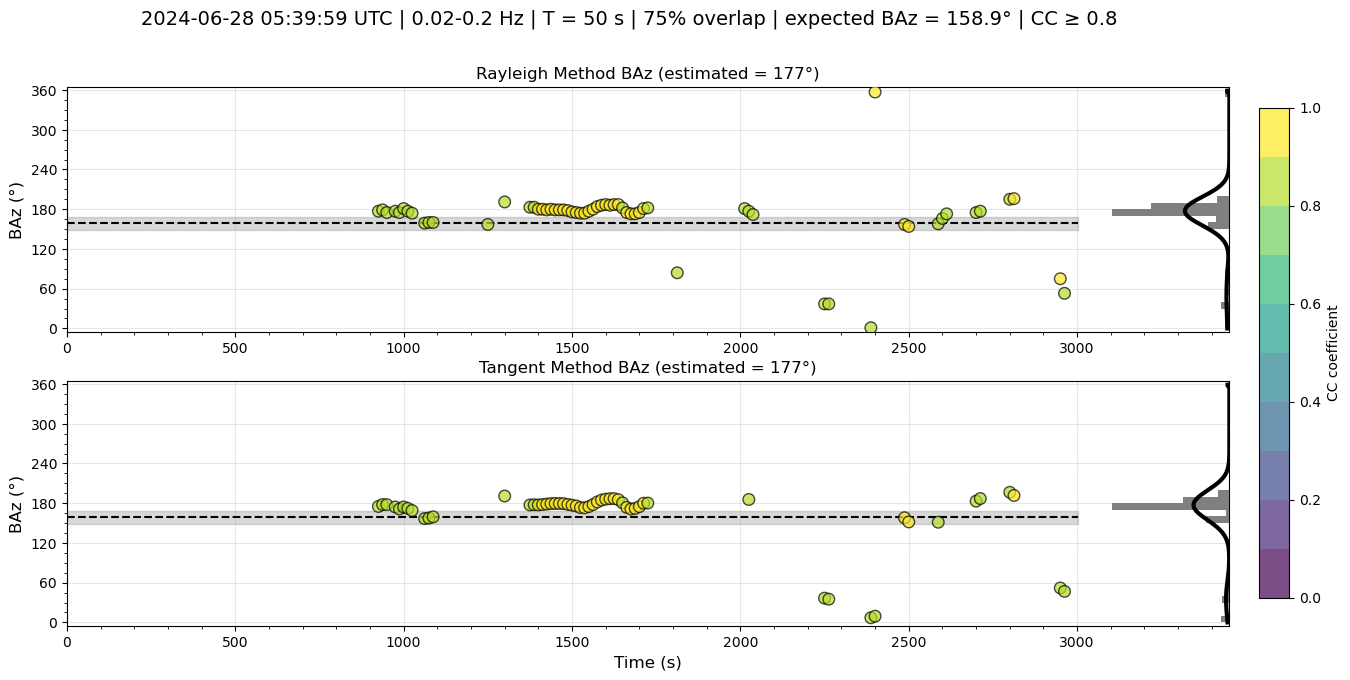

In [38]:
fig, results = sd.compare_backazimuth_methods(
    Twin=Twindow,
    Toverlap=Toverlap,
    cc_threshold=cc_threshold,
    baz_theo=ev['backazimuth'],
    cc_method='mid',
    plot=True,
    output=True,
    wave_types=['rayleigh', 'tangent']
)

if save_figs:
    fig.savefig(f"{config['path_to_figures']}{config['project']}_VEL_backazimuth_methods_mid.png", bbox_inches='tight')


In [29]:
# sd.polarity_stream(pol_dict={"HE": -1}, raw=False)

In [30]:
# # compute backazimuth
# baz_results = sd.compute_backazimuth(
#     wave_type='tangent',
#     baz_step=1,
#     baz_win_sec=Twindow,
#     baz_win_overlap=Toverlap,
#     out=True,
#     tangent_components="acceleration"
# )

# fig = plot_backazimuth_results(
#     sd,
#     baz_results,
#     wave_type='rayleigh',
#     baz_theo=ev['backazimuth'],
#     cc_threshold=cc_threshold,  # optional
#     cc_method='mid',
#     unitscale='nano', # for rotation rate
#     data_type="velocity"
# )

### Estimate Phase Velocities

In [31]:
# estimate phase velocities
results_vel1 = sd.compute_velocities(
    wave_type='rayleigh',
    win_time_s=Twindow,
    overlap=Toverlap,
    baz=ev['backazimuth'],
    method="ransac"

)

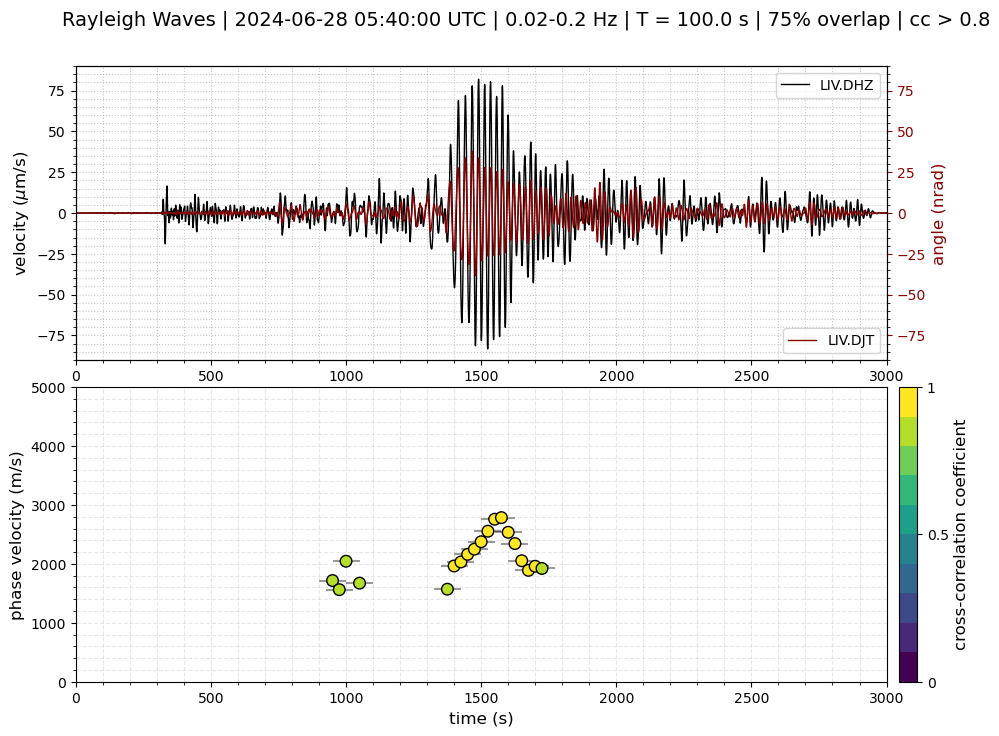

In [32]:
fig = plot_velocities(
    sd,
    results_vel1,
    cc_threshold=cc_threshold,
    vmax=5000,
    data_type="velocity"
);

if save_figs:
    fig.savefig(f"{config['path_to_figures']}{config['project']}_VEL_velocities.png", bbox_inches='tight')

In [33]:
rayleigh_dispersion_vel = sd.compute_dispersion_curve(
    wave_type="rayleigh",
    fmin=0.02,              # Minimum frequency in Hz
    fmax=0.2,               # Maximum frequency in Hz
    octave_fraction=2,      # 1/3 octave bands
    window_factor=6.0,      # Time window = window_factor / fc
    cc_threshold=cc_threshold,       # Cross-correlation threshold
    baz_step=1,             # Backazimuth search step (degrees)
    time_window_overlap=0.75,    # Backazimuth window overlap
    velocity_method='odr',  # Regression method: 'odr', 'ransac', etc.
    zero_intercept=True,    # Force zero intercept
    verbose=False,            # Print progress
    n_jobs=4            # Number of parallel jobs
)


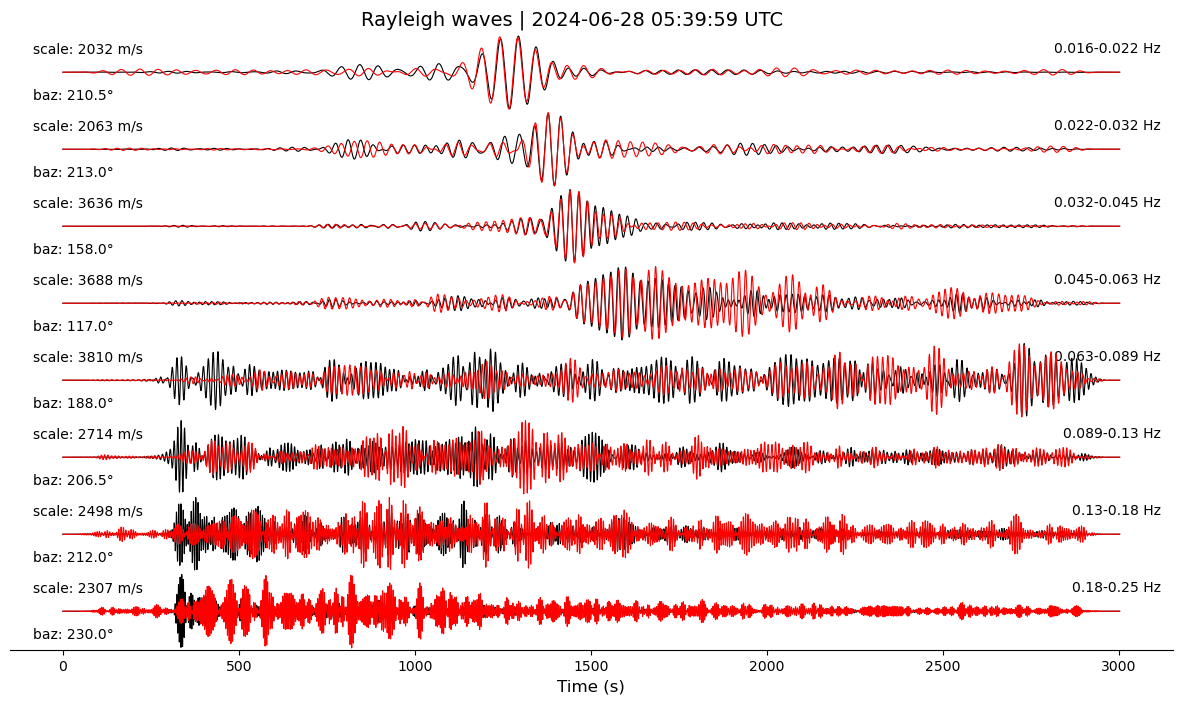

In [34]:
fig_traces_rayleigh = plot_dispersion_traces(
    dispersion_results=rayleigh_dispersion_vel,
    unitscale="nano",
    data_type="velocity"
)

fig_traces_rayleigh.set_size_inches(15,8)
plt.show();

if save_figs:
    fig_traces_rayleigh.savefig(f"{config['path_to_figures']}{config['project']}_VEL_dispersion_traces.png", bbox_inches='tight')


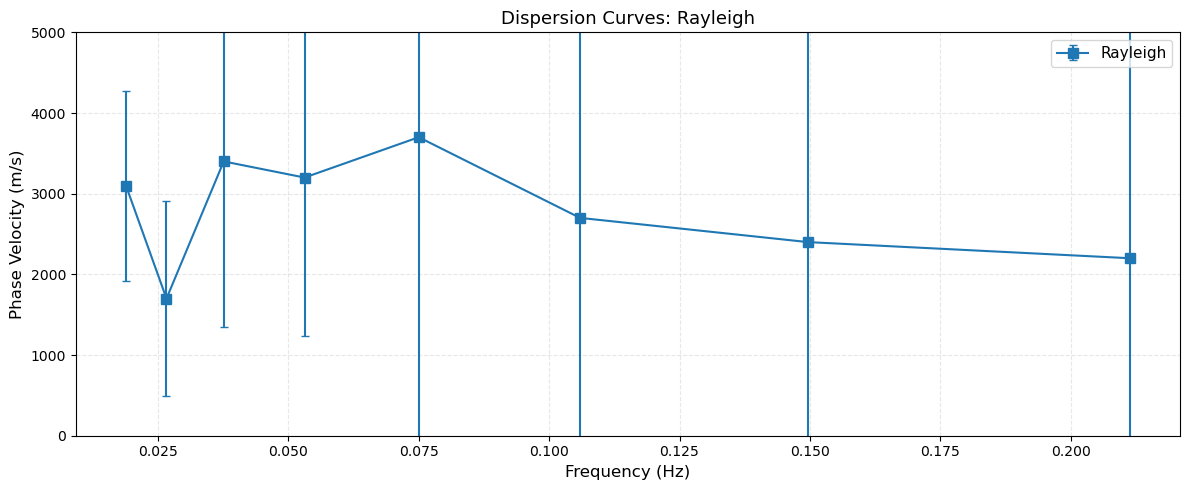

In [35]:
fig = plot_dispersion_curves(
    rayleigh_results=rayleigh_dispersion_vel,
    figsize=(12, 5),
    show_errors=True
)

if save_figs:
    fig.savefig(f"{config['path_to_figures']}{config['project']}_VEL_dispersion_curve.png", bbox_inches='tight')


### Make Plot of Full Event Analysis

Theoretical P-arrival: 2024-06-28T05:45:19.658710Z
Theoretical S-arrival: 2024-06-28T05:52:21.828320Z


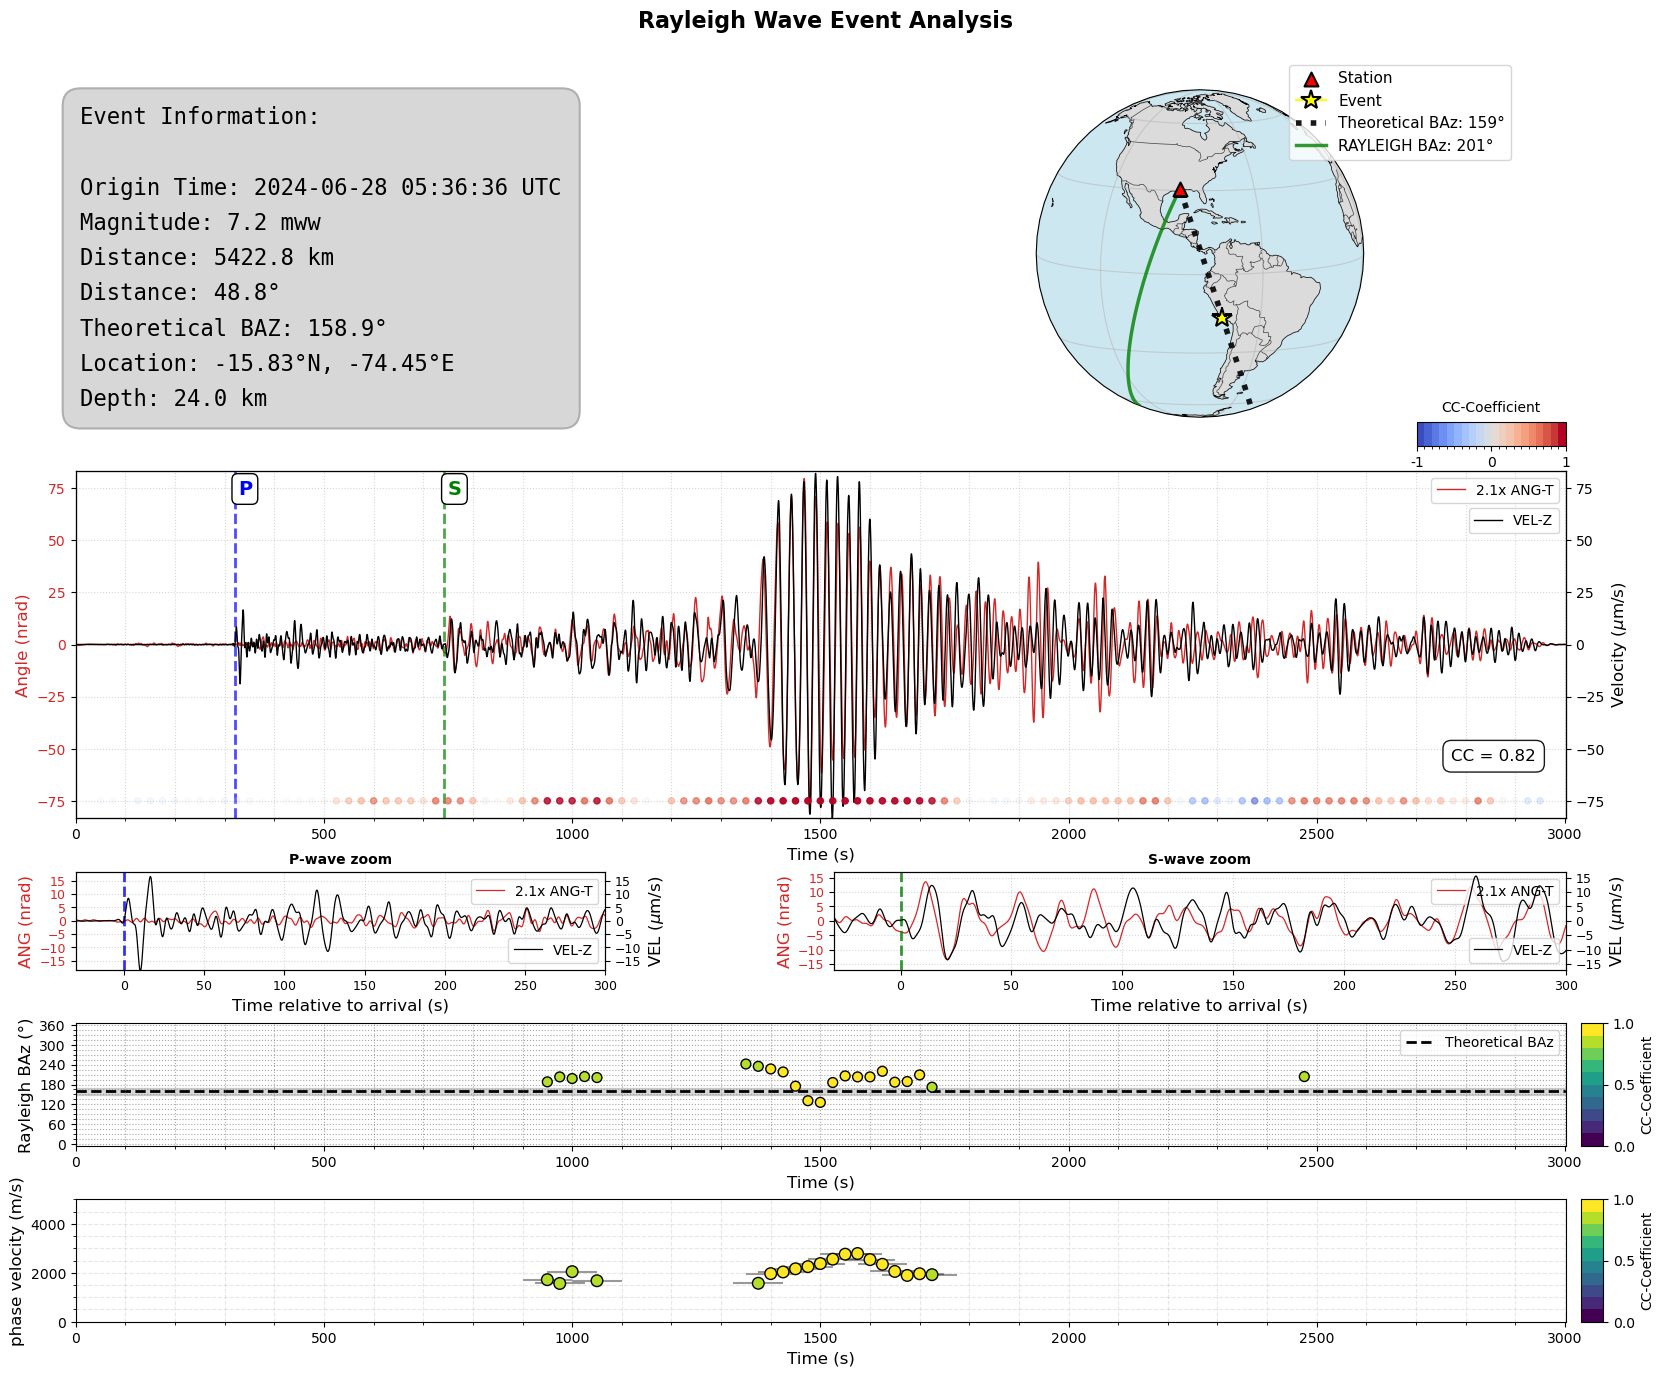

In [36]:
fig = plot_event_overview(
    sd, 
    baz_results,
    results_vel1,
    event_info=ev,
    wave_type='rayleigh',
    baz_theo=ev['backazimuth'],
    cc_method='max',
    cc_threshold=cc_threshold,
    vmax=5000,
    twin_sec=Twindow,
    twin_overlap=Toverlap,
    zoom_t1=30,
    zoom_t2=300,
    rot_scale_factor=2.1,
    data_type="velocity"
);

if save_figs:
    fig.savefig(f"{config['path_to_figures']}{config['project']}_VEL_event_overview_max.png", bbox_inches='tight')


Theoretical P-arrival: 2024-06-28T05:45:19.658710Z
Theoretical S-arrival: 2024-06-28T05:52:21.828320Z


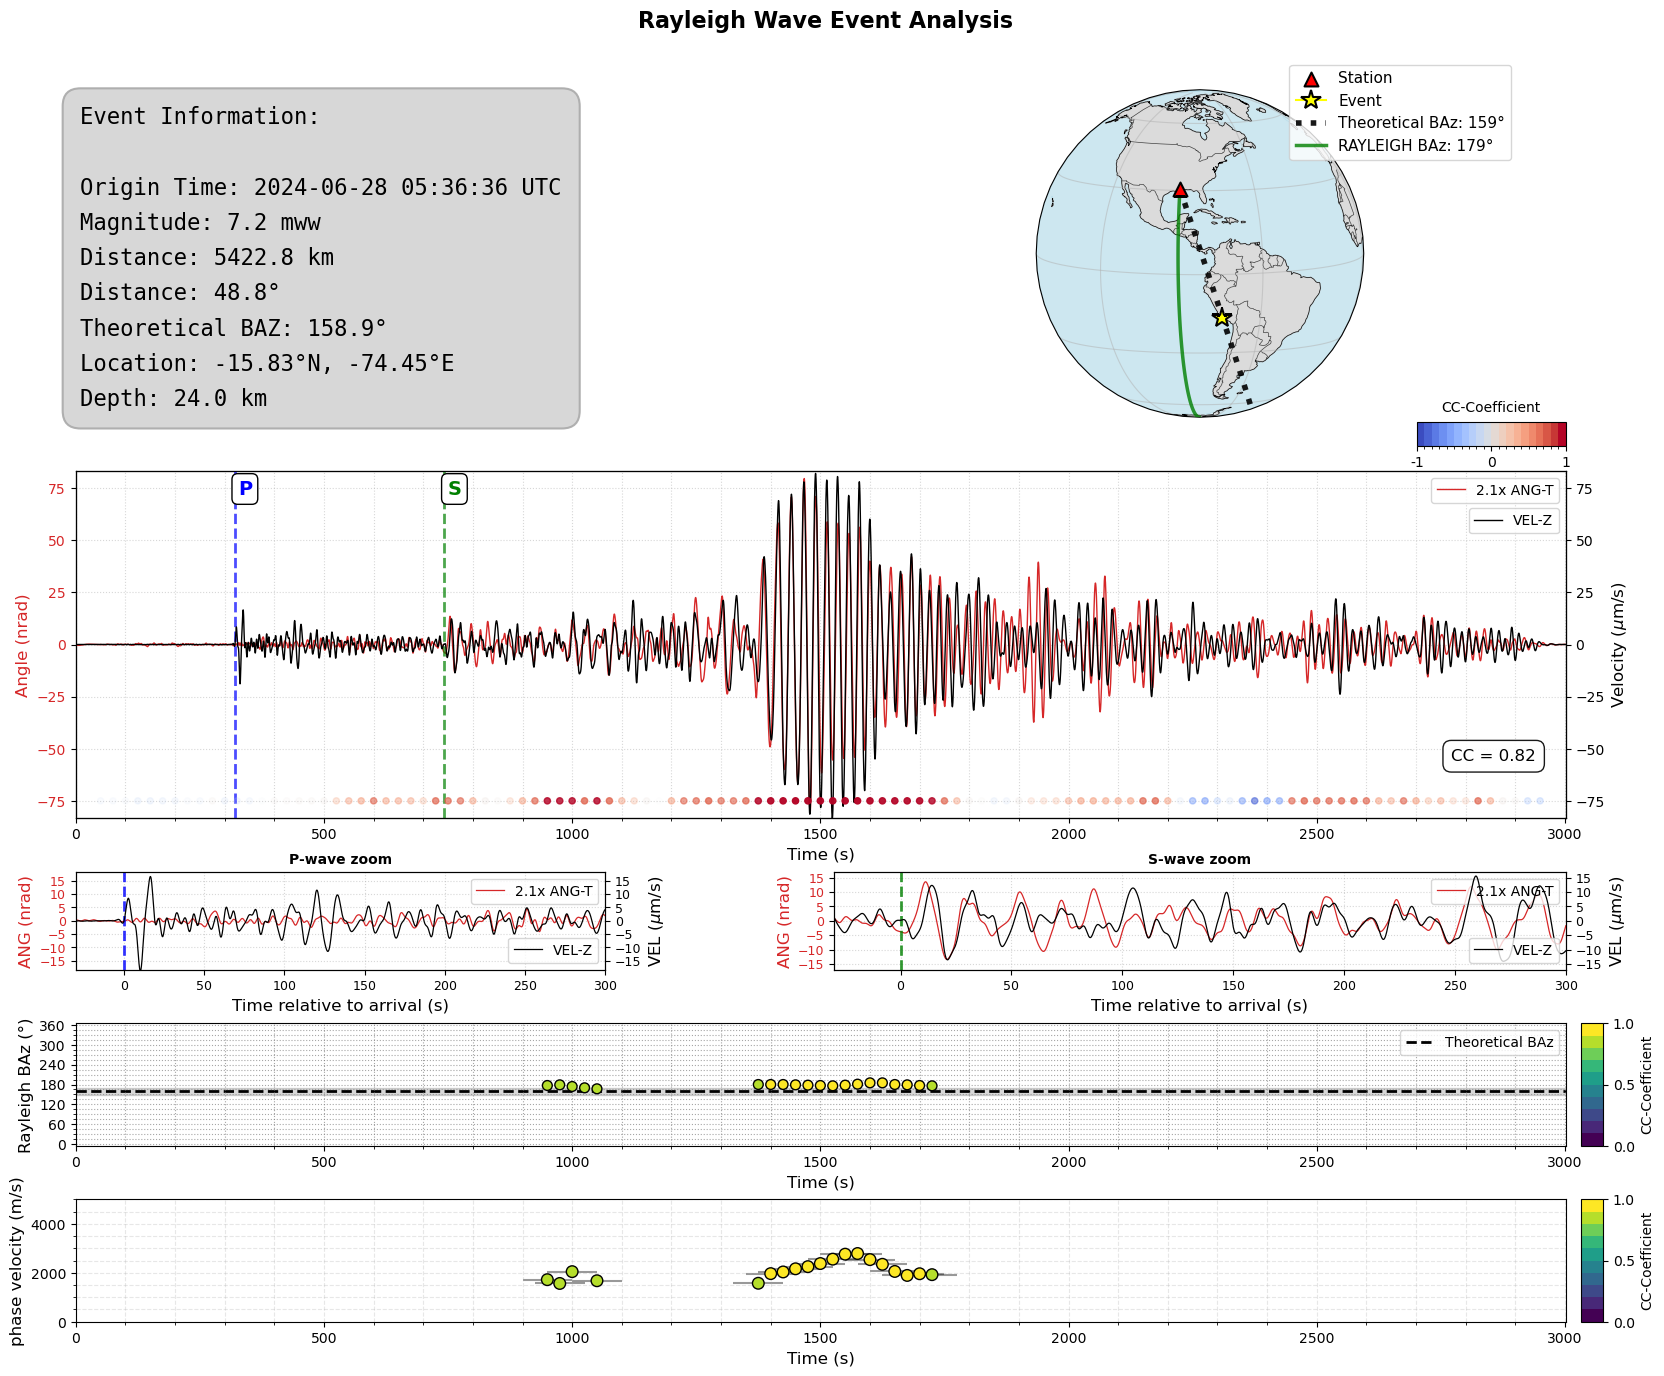

In [37]:
fig = plot_event_overview(
    sd, 
    baz_results,
    results_vel1,
    event_info=ev,
    wave_type='rayleigh',
    baz_theo=ev['backazimuth'],
    cc_method='mid',
    cc_threshold=cc_threshold,
    vmax=5000,
    twin_sec=Twindow,
    twin_overlap=Toverlap,
    zoom_t1=30,
    zoom_t2=300,
    rot_scale_factor=2.1,
    data_type="velocity"
);

if save_figs:
    fig.savefig(f"{config['path_to_figures']}{config['project']}_VEL_event_overview_mid.png", bbox_inches='tight')


## 2) Turn to Acceleration and Rotation Rate

In [38]:
# sd.st.select(station="LIV", channel="*JE")[0].data *= -1

east_rotation_rate = sd.st.select(station="LIV", channel="*JE").differentiate()[0].data
north_rotation_rate = sd.st.select(station="LIV", channel="*JN").differentiate()[0].data
sd.st.select(station="LIV", channel="*JE")[0].data = east_rotation_rate
sd.st.select(station="LIV", channel="*JN")[0].data = north_rotation_rate

vertical_acceleration = sd.st.select(station="LIV", channel="*HZ").differentiate()[0].data
north_acceleration = sd.st.select(station="LIV", channel="*HN").differentiate()[0].data
east_acceleration = sd.st.select(station="LIV", channel="*HE").differentiate()[0].data
sd.st.select(station="LIV", channel="*HN")[0].data = north_acceleration
sd.st.select(station="LIV", channel="*HE")[0].data = east_acceleration
sd.st.select(station="LIV", channel="*HZ")[0].data = vertical_acceleration

# sd.st.select(station="LIV", channel="*HZ")[0].data *= -1


# Plotting

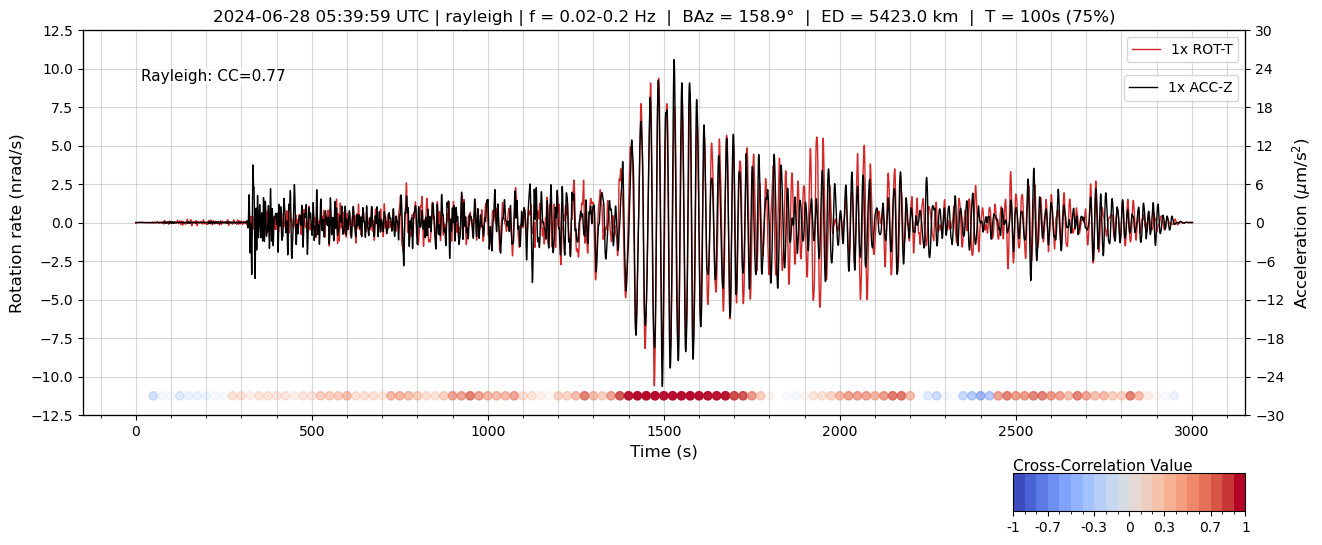

In [39]:
fig = plot_waveform_cc(
    sd_object=sd,
    fmin=fmin,
    fmax=fmax,
    twin_sec=Twindow,
    twin_overlap=Toverlap,
    wave_type="rayleigh",
    runit=config['runit'],
    tunit=config['tunit']
)

if save_figs:
    fig.savefig(f"{config['path_to_figures']}{config['project']}_ACC_waveform_cc.png", bbox_inches='tight')


In [40]:
# compute backazimuth
baz_results_rayleigh = sd.compute_backazimuth(
    wave_type='rayleigh',
    baz_step=1,
    baz_win_sec=Twindow,
    baz_win_overlap=Toverlap,
    out=True
)


baz_max = 205, baz_std = 23


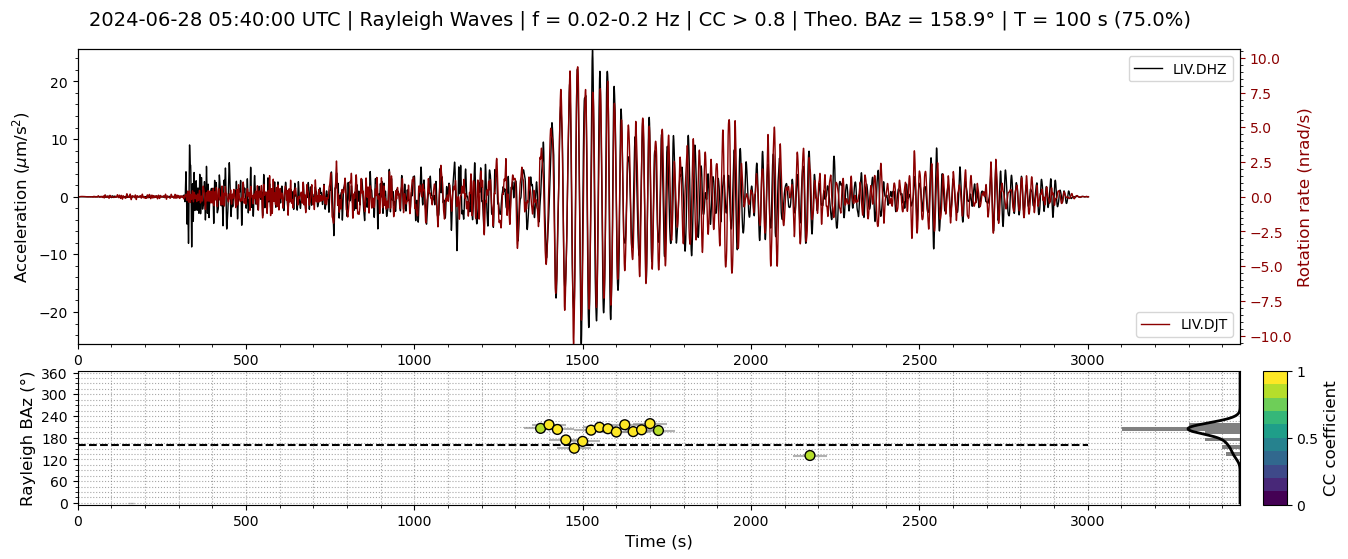

In [41]:
fig = plot_backazimuth_results(
    sd,
    baz_results=baz_results_rayleigh,
    wave_type='rayleigh',
    baz_theo=ev['backazimuth'],
    cc_threshold=cc_threshold,  # optional
    cc_method='max',
    unitscale='nano' # for rotation rate
)

if save_figs:
    fig.savefig(f"{config['path_to_figures']}{config['project']}_ACC_backazimuth_max.png", bbox_inches='tight')

baz_max = 179, baz_std = 4


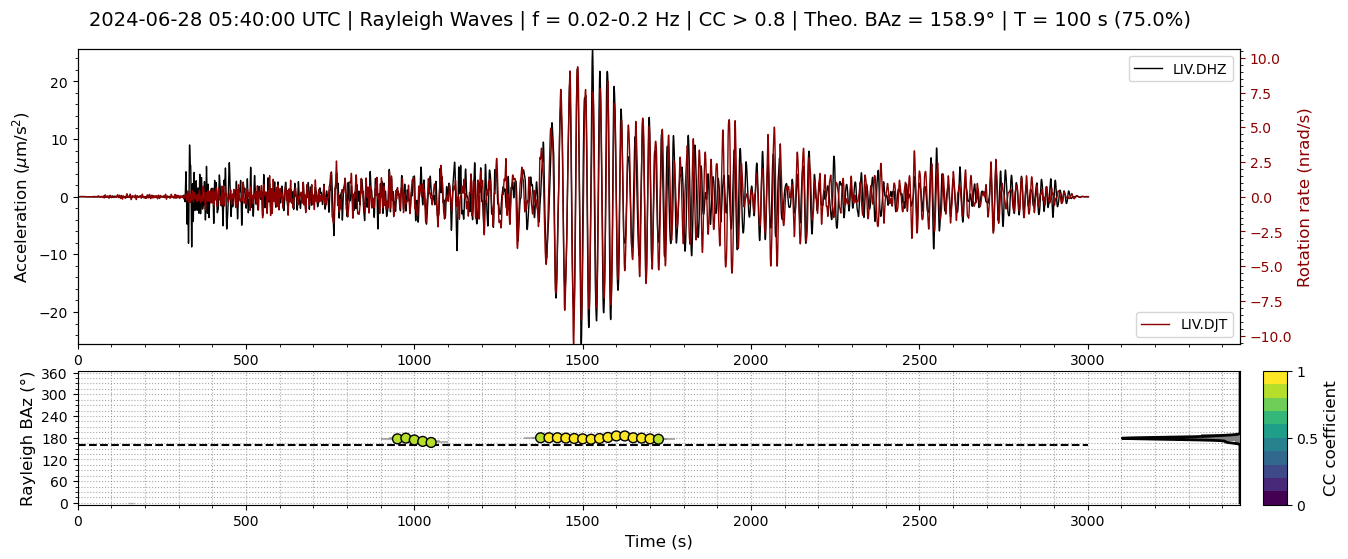

In [42]:
fig = plot_backazimuth_results(
    sd,
    baz_results,
    wave_type='rayleigh',
    baz_theo=ev['backazimuth'],
    cc_threshold=cc_threshold,  # optional
    cc_method='mid',
    unitscale='nano', # for rotation rate
)

if save_figs:
    fig.savefig(f"{config['path_to_figures']}{config['project']}_ACC_backazimuth_mid.png", bbox_inches='tight')

Using precomputed rayleigh backazimuth results

Estimated BAz Rayleigh = 179° (CC ≥ 0.8)
Using precomputed tangent backazimuth results

Estimated BAz Tangent = 178° (CC ≥ 0.8)


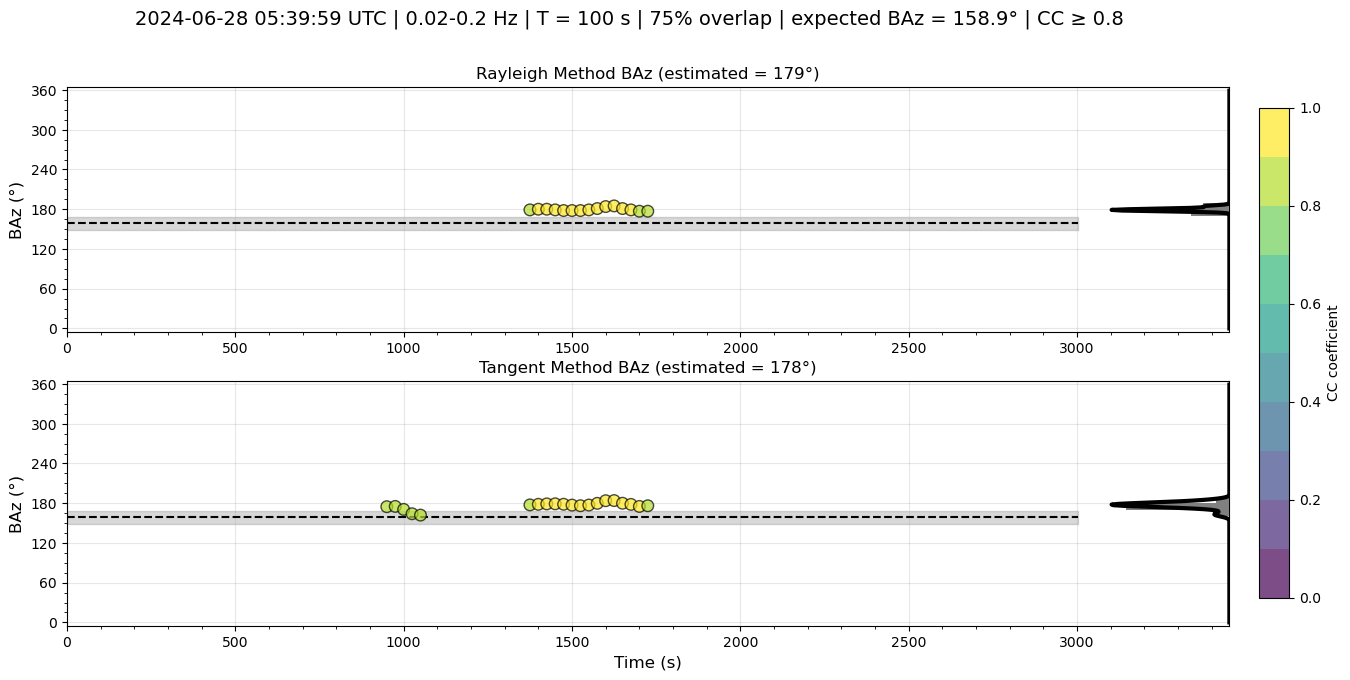

In [43]:
fig, results = sd.compare_backazimuth_methods(
    Twin=Twindow,
    Toverlap=Toverlap,
    cc_threshold=cc_threshold,
    cc_method='mid',
    baz_theo=ev['backazimuth'],
    plot=True,
    output=True,
    wave_types=['rayleigh', 'tangent']
)

if save_figs:
    fig.savefig(f"{config['path_to_figures']}{config['project']}_ACC_backazimuth_methods.png", bbox_inches='tight')


In [44]:
# estimate phase velocities
results_vel1 = sd.compute_velocities(
    wave_type='rayleigh',
    win_time_s=Twindow,
    overlap=Toverlap,
    baz=ev['backazimuth'],
    method="ransac"
)


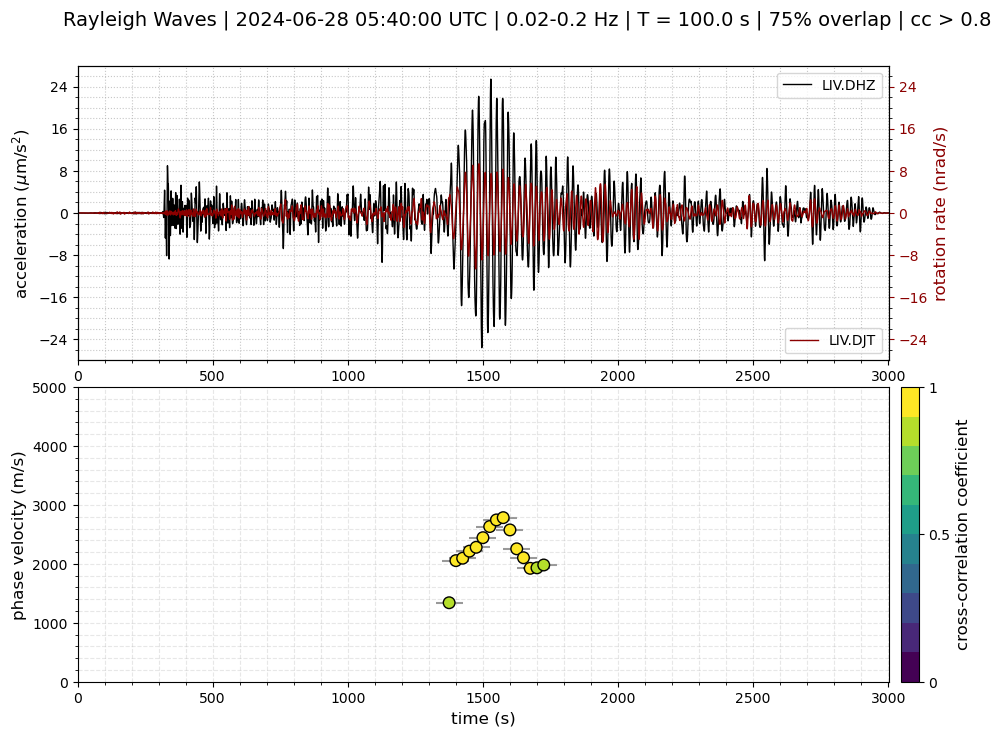

In [45]:
fig = plot_velocities(
    sd,
    results_vel1,
    cc_threshold=cc_threshold,
    vmax=5000
);

if save_figs:
    fig.savefig(f"{config['path_to_figures']}{config['project']}_ACC_velocities.png", bbox_inches='tight')

Theoretical P-arrival: 2024-06-28T05:45:19.658710Z
Theoretical S-arrival: 2024-06-28T05:52:21.828320Z


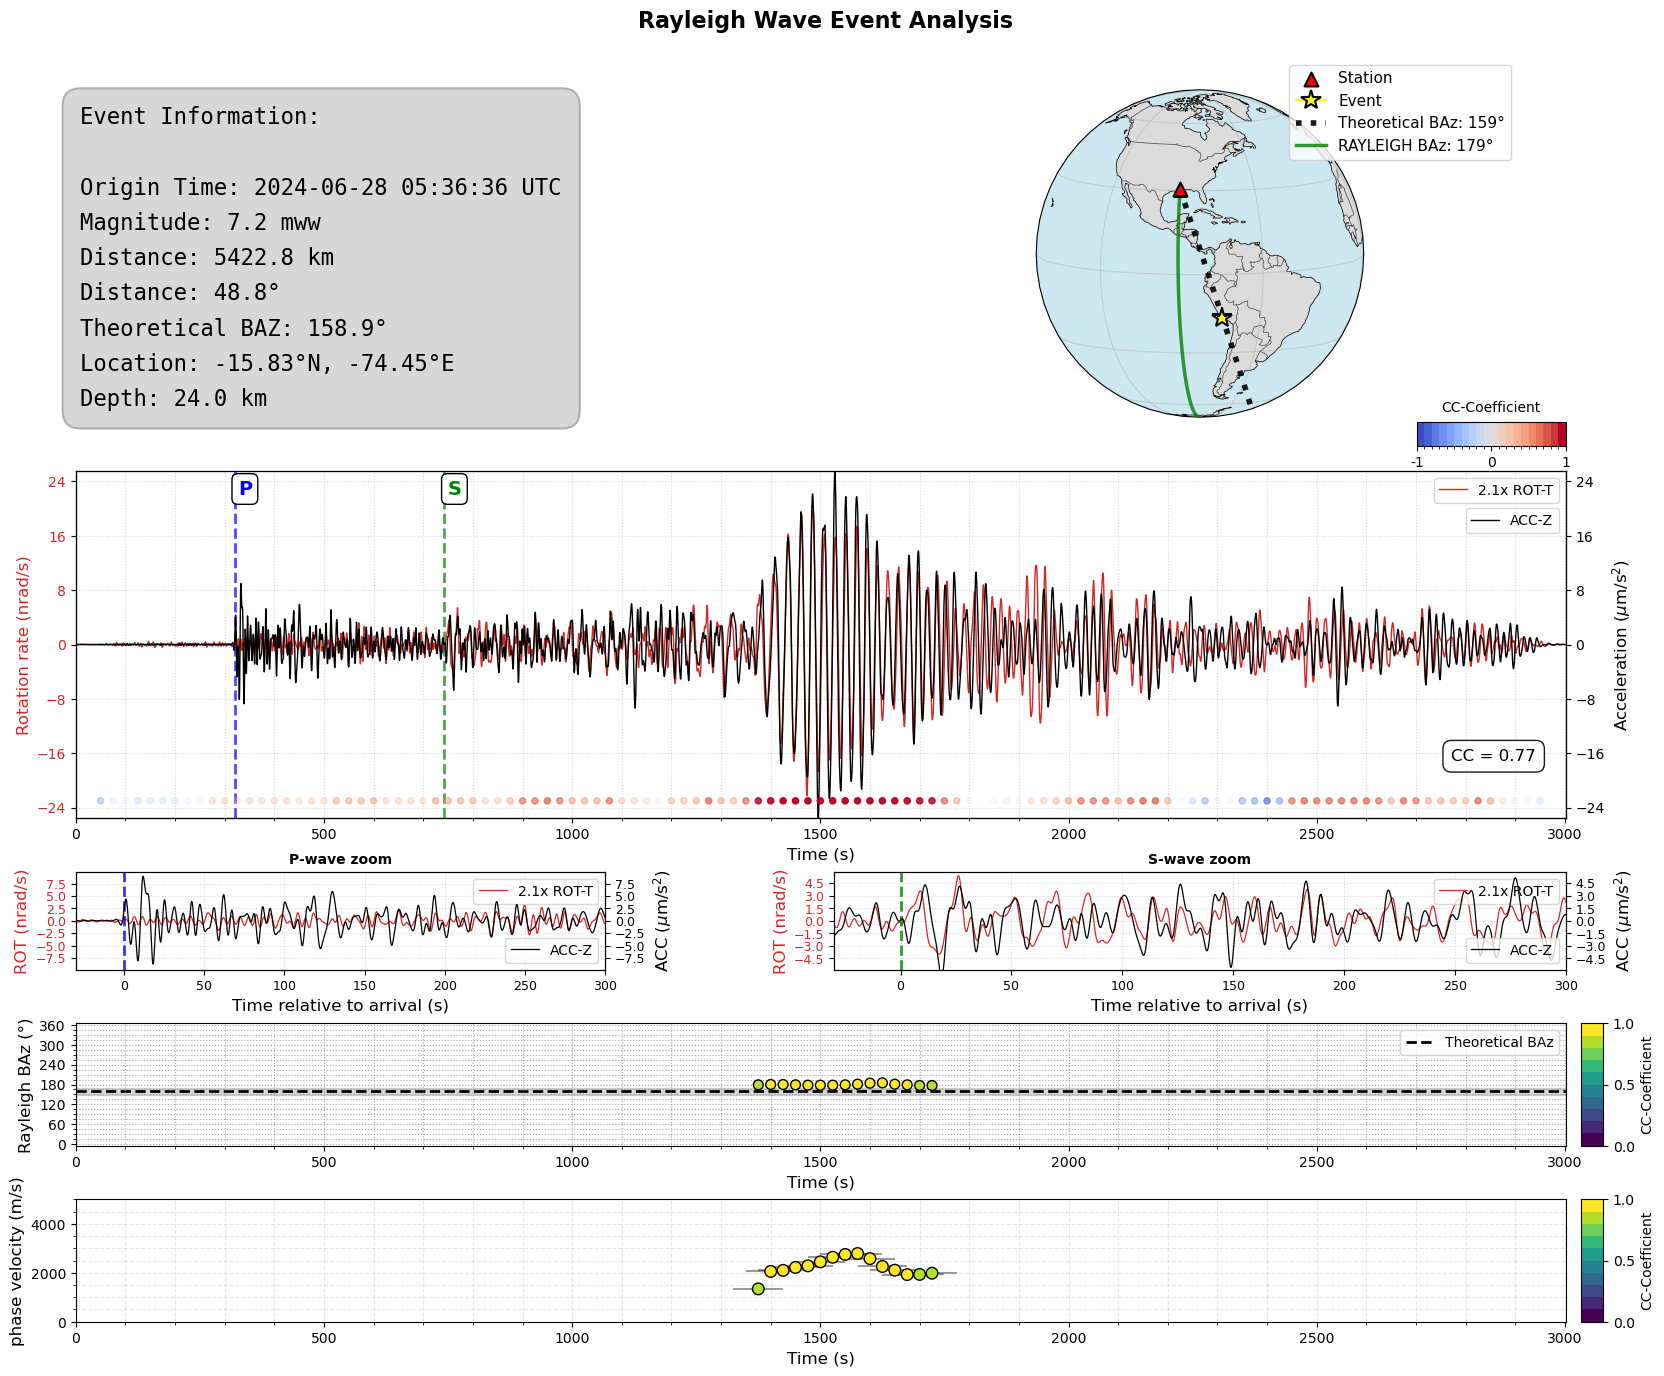

In [46]:
from sixdegrees.plots.plot_event_overview import plot_event_overview

fig = plot_event_overview(sd, 
    baz_results_rayleigh,
    results_vel1,
    event_info=ev,
    wave_type='rayleigh',
    baz_theo=ev['backazimuth'],
    cc_method='mid',
    cc_threshold=cc_threshold,
    vmax=5000,
    twin_sec=Twindow,
    twin_overlap=Toverlap,
    zoom_t1=30,
    zoom_t2=300,
    rot_scale_factor=2.1,
);

if save_figs:
    fig.savefig(f"{config['path_to_figures']}{config['project']}_ACC_event_overview.png", bbox_inches='tight')


### Compute Dispersion Curve

In [53]:
# Compute dispersion curve for Rayleigh waves
rayleigh_results = sd.compute_dispersion_curve(
    wave_type="rayleigh",
    fmin=0.02,              # Minimum frequency in Hz
    fmax=0.2,               # Maximum frequency in Hz
    octave_fraction=2,      # 1/3 octave bands
    window_factor=6.0,      # Time window = window_factor / fc
    cc_threshold=0.8,       # Cross-correlation threshold
    baz_step=1,             # Backazimuth search step (degrees)
    time_window_overlap=0.75,    # Backazimuth window overlap
    velocity_method='ransac',  # Regression method: 'odr', 'ransac', etc.
    zero_intercept=False,    # Force zero intercept
    verbose=False,            # Print progress
    n_jobs=5            # Number of parallel jobs
)

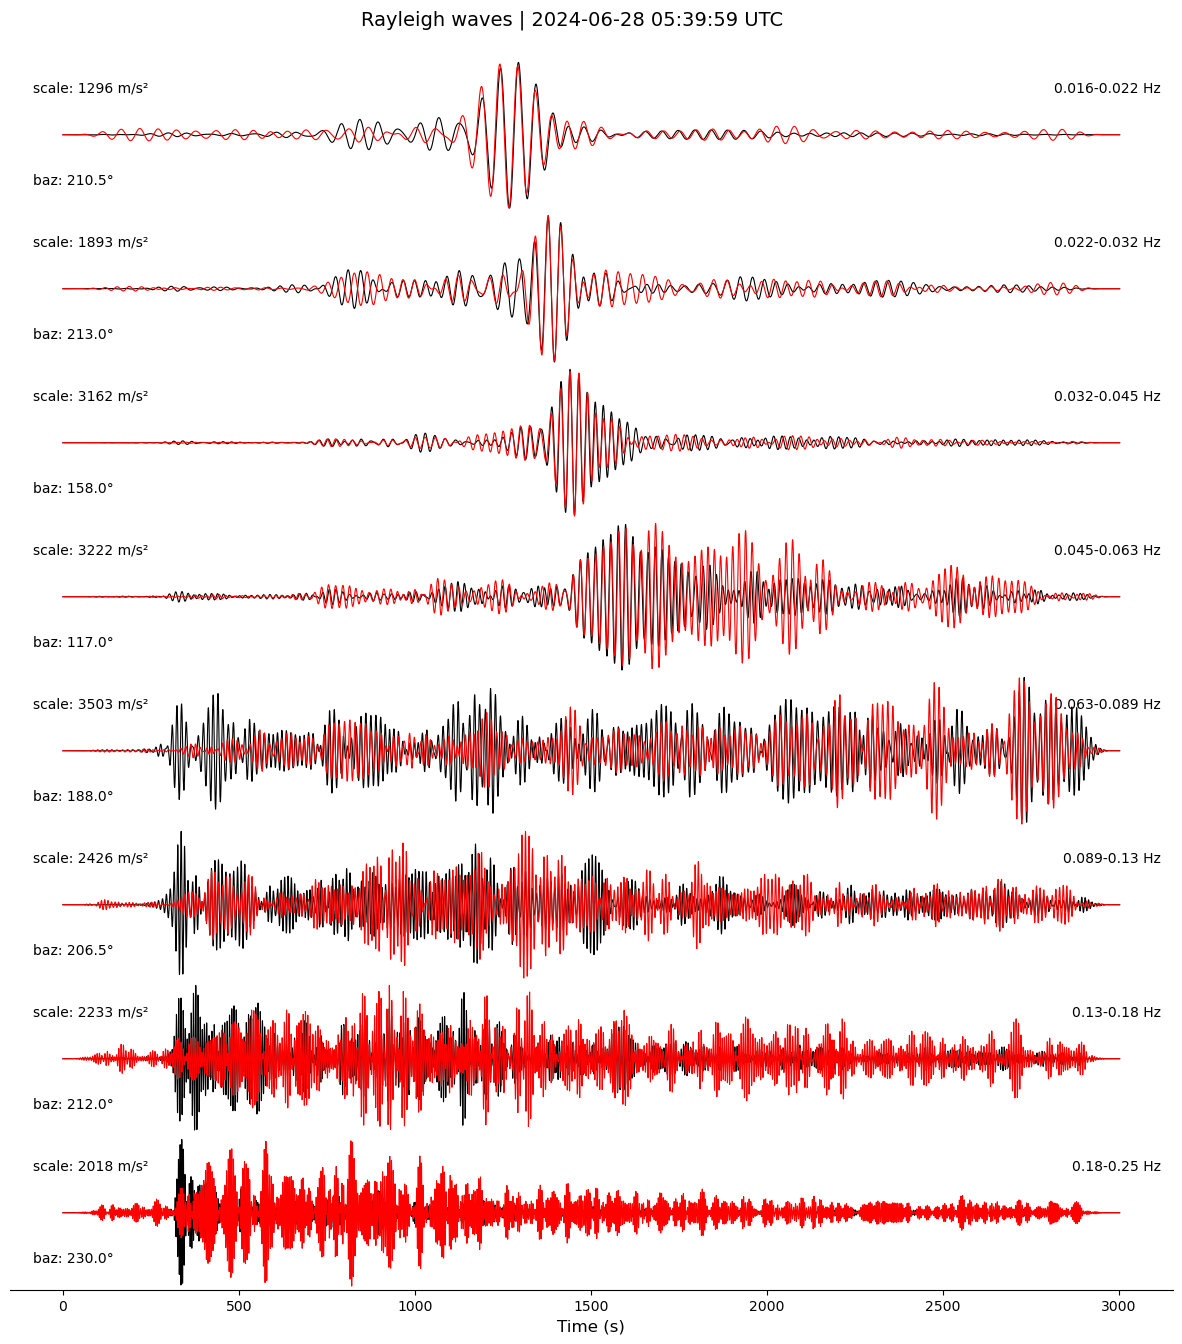

In [54]:
fig_traces_rayleigh = plot_dispersion_traces(
    dispersion_results=rayleigh_results,
    unitscale="nano",
    data_type="acceleration"
)

(0.0, 5000.0)

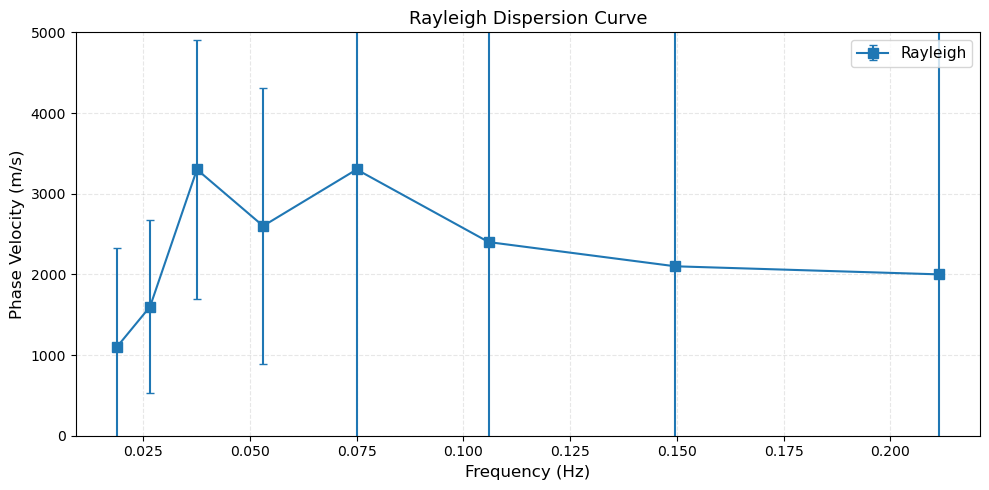

In [55]:
fig_curves = plot_dispersion_curves(
    rayleigh_results=rayleigh_results,
    figsize=(10, 5),
    xlog=False,                 # Logarithmic x-axis
    ylog=False,                 # Logarithmic y-axis
    title="Rayleigh Dispersion Curve",  # Optional
    show_errors=True            # Show error bars from KDE deviations
)
plt.ylim(0, 5000)